# Final Assignment — Telecom Churn: Model and Business Proposal

**Client:** Company A (anonymous wireless operator), ~100,000 customers.
**Goal:** Use the data to define a concrete business problem, build and evaluate machine learning models, and quantify the impact of a recommendation.

**Notebook structure**
0. Market context and sources
1. Setup (runs on Google Colab or locally)
2. Load and validate the data
3. Exploratory data analysis (EDA)
4. Problem definition and target choice
5. Feature engineering and leakage checks
6. Models: training, cross-validation, test evaluation and robustness check
7. Model interpretation
8. Business impact and proposal
9. Conclusion and references

**Before you run it on Colab:** upload the whole `Final Assignment` folder to *My Drive* (keeping the `telecom` subfolder with `Client.csv` and `Record.csv`). The notebook searches for the data automatically. If it cannot find it, set `DATA_DIR` manually in Section 1.2.

## 0. Market context

Telecom operators spend heavily to win customers, so losing one is costly. Three external facts frame the problem (full references at the end of the notebook):

- **Retention is cheaper than acquisition.** Harvard Business Review reports that acquiring a new customer costs about five to 25 times more than keeping an existing one, depending on the industry [2].
- **Small retention gains matter for profit.** Reichheld and Sasser (1990) found that retaining a few more customers can raise profits sharply [1]. Later authors dispute the size of this effect [7], so we use it only as context, not as a forecast.
- **Churn is a real and rising concern for US carriers.** AT&T reported postpaid phone churn of 0.89% in Q1 2026 [3] and 0.86% in Q2 2026 [4]. These are monthly rates for the whole base, so they are much lower than the outcome in our dataset (Section 3.1). The comparison shows that the dataset is a sample built for modelling, not a copy of a carrier's full base.

**Implication for the client:** a model that ranks customers by churn risk lets a retention team spend a fixed budget on the customers most likely to leave, instead of contacting everyone.

## 1. Setup

### 1.1 Imports and settings

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score, precision_score,
    recall_score, accuracy_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve,
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 140)
print("pandas:", pd.__version__, "| numpy:", np.__version__)

pandas: 3.0.6 | numpy: 2.5.4


### 1.2 Google Drive and data location

On Colab, Drive is mounted so the data can be read. Locally this cell is skipped.

In [2]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running on Colab:", IN_COLAB)

Running on Colab: False


In [3]:
# Set DATA_DIR yourself if the automatic search below does not find the files.
# Example: DATA_DIR = Path("/content/drive/MyDrive/Final Assignment/telecom")
DATA_DIR = None

if DATA_DIR is None:
    candidates = [
        os.environ.get("TELECOM_DATA_DIR"),
        Path.cwd() / "telecom",
        Path.cwd() / "Final Assignment" / "telecom",
        Path("/content/drive/MyDrive/Final Assignment/telecom"),
        Path("/content/drive/MyDrive/05. Final Assignment (due Nov 28)/Final Assignment/telecom"),
    ]
    for cand in candidates:
        if cand and (Path(cand) / "Client.csv").exists() and (Path(cand) / "Record.csv").exists():
            DATA_DIR = Path(cand)
            break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Client.csv and Record.csv were not found. Set DATA_DIR in the cell above."
    )
print("Data folder:", DATA_DIR)

Data folder: /home/claude/build/telecom


## 2. Load and validate the data

The data is split across two tables that share `Customer_ID`:
- `Client.csv`: account-level information (tenure, plan, handset, demographics).
- `Record.csv`: usage, billing and call-quality metrics, plus the `churn` outcome.

Before merging, we check that each customer appears exactly once in each table. Otherwise the merge could silently duplicate rows.

**Data provenance.** The column names (for example `rev_Mean`, `mou_Mean`, `drop_vce_Mean`, `churn`) follow the convention of the churn data published by the Teradata Center for Customer Relationship Management at Duke University [5]. The course should confirm the exact source of this copy before submission.

In [4]:
client = pd.read_csv(DATA_DIR / "Client.csv")
record = pd.read_csv(DATA_DIR / "Record.csv")

assert client["Customer_ID"].is_unique, "Duplicate Customer_ID in Client.csv"
assert record["Customer_ID"].is_unique, "Duplicate Customer_ID in Record.csv"

df = record.merge(client, on="Customer_ID", how="inner", validate="one_to_one")
print("Client table:", client.shape)
print("Record table:", record.shape)
print("Merged table:", df.shape)
assert len(df) == len(record) == len(client), "Some customers are missing from one table"

Client table: (100000, 50)
Record table: (100000, 51)
Merged table: (100000, 100)


## 3. Exploratory data analysis

EDA answers three questions: how big and complete is the data, what does the outcome look like, and which factors relate to churn. Those answers decide the target, the features and the preprocessing.

### 3.1 Target distribution

churn
0    50438
1    49562
Name: count, dtype: int64

churn
0    50.44 %
1    49.56 %
Name: proportion, dtype: str


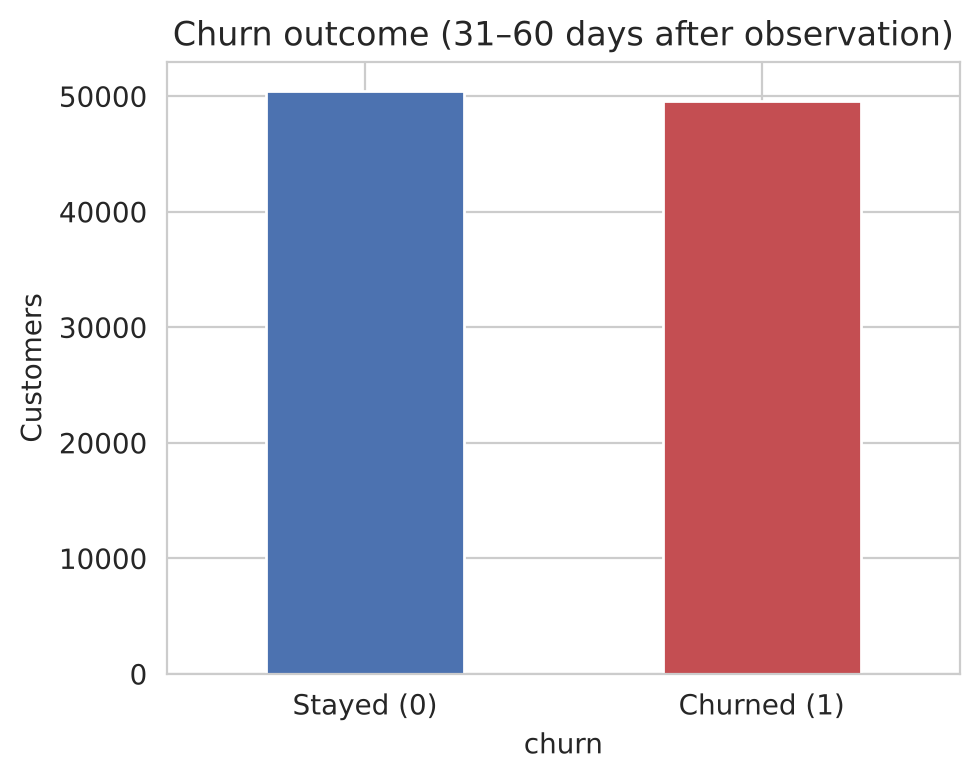

In [5]:
TARGET = "churn"
print(df[TARGET].value_counts())
print()
print((df[TARGET].value_counts(normalize=True) * 100).round(2).astype(str) + " %")

plt.figure(figsize=(5, 4))
df[TARGET].value_counts().sort_index().plot.bar(color=["#4C72B0", "#C44E52"])
plt.xticks([0, 1], ["Stayed (0)", "Churned (1)"], rotation=0)
plt.ylabel("Customers")
plt.title("Churn outcome (31–60 days after observation)")
plt.tight_layout()
plt.show()

**Reading the target:** the classes are almost exactly balanced (about 50% churn). This is far higher than the monthly rates carriers report (about 0.9% [3][4]). The outcome here is churn within a 31–60 day window in a sampled dataset, so the two numbers are not directly comparable, and the base rate should be treated as a property of this sample. Accuracy would be misleading for a rare-event problem, but here it is less of a concern. We still report precision, recall, F1 and PR-AUC so the results do not depend on the class balance.

### 3.4 Handset age (`eqpdays`) and churn

Handset age is a factor the business can act on: a retention or upgrade offer can address it directly. Here we group customers into deciles of handset age and compare churn rates.

eqpdays
(-5.001, 94.0]     40.0
(94.0, 188.0]      43.1
(188.0, 240.0]     37.5
(240.0, 300.0]     37.3
(300.0, 342.0]     61.0
(342.0, 395.0]     58.1
(395.0, 475.0]     52.7
(475.0, 589.0]     53.3
(589.0, 742.0]     54.4
(742.0, 1823.0]    58.3


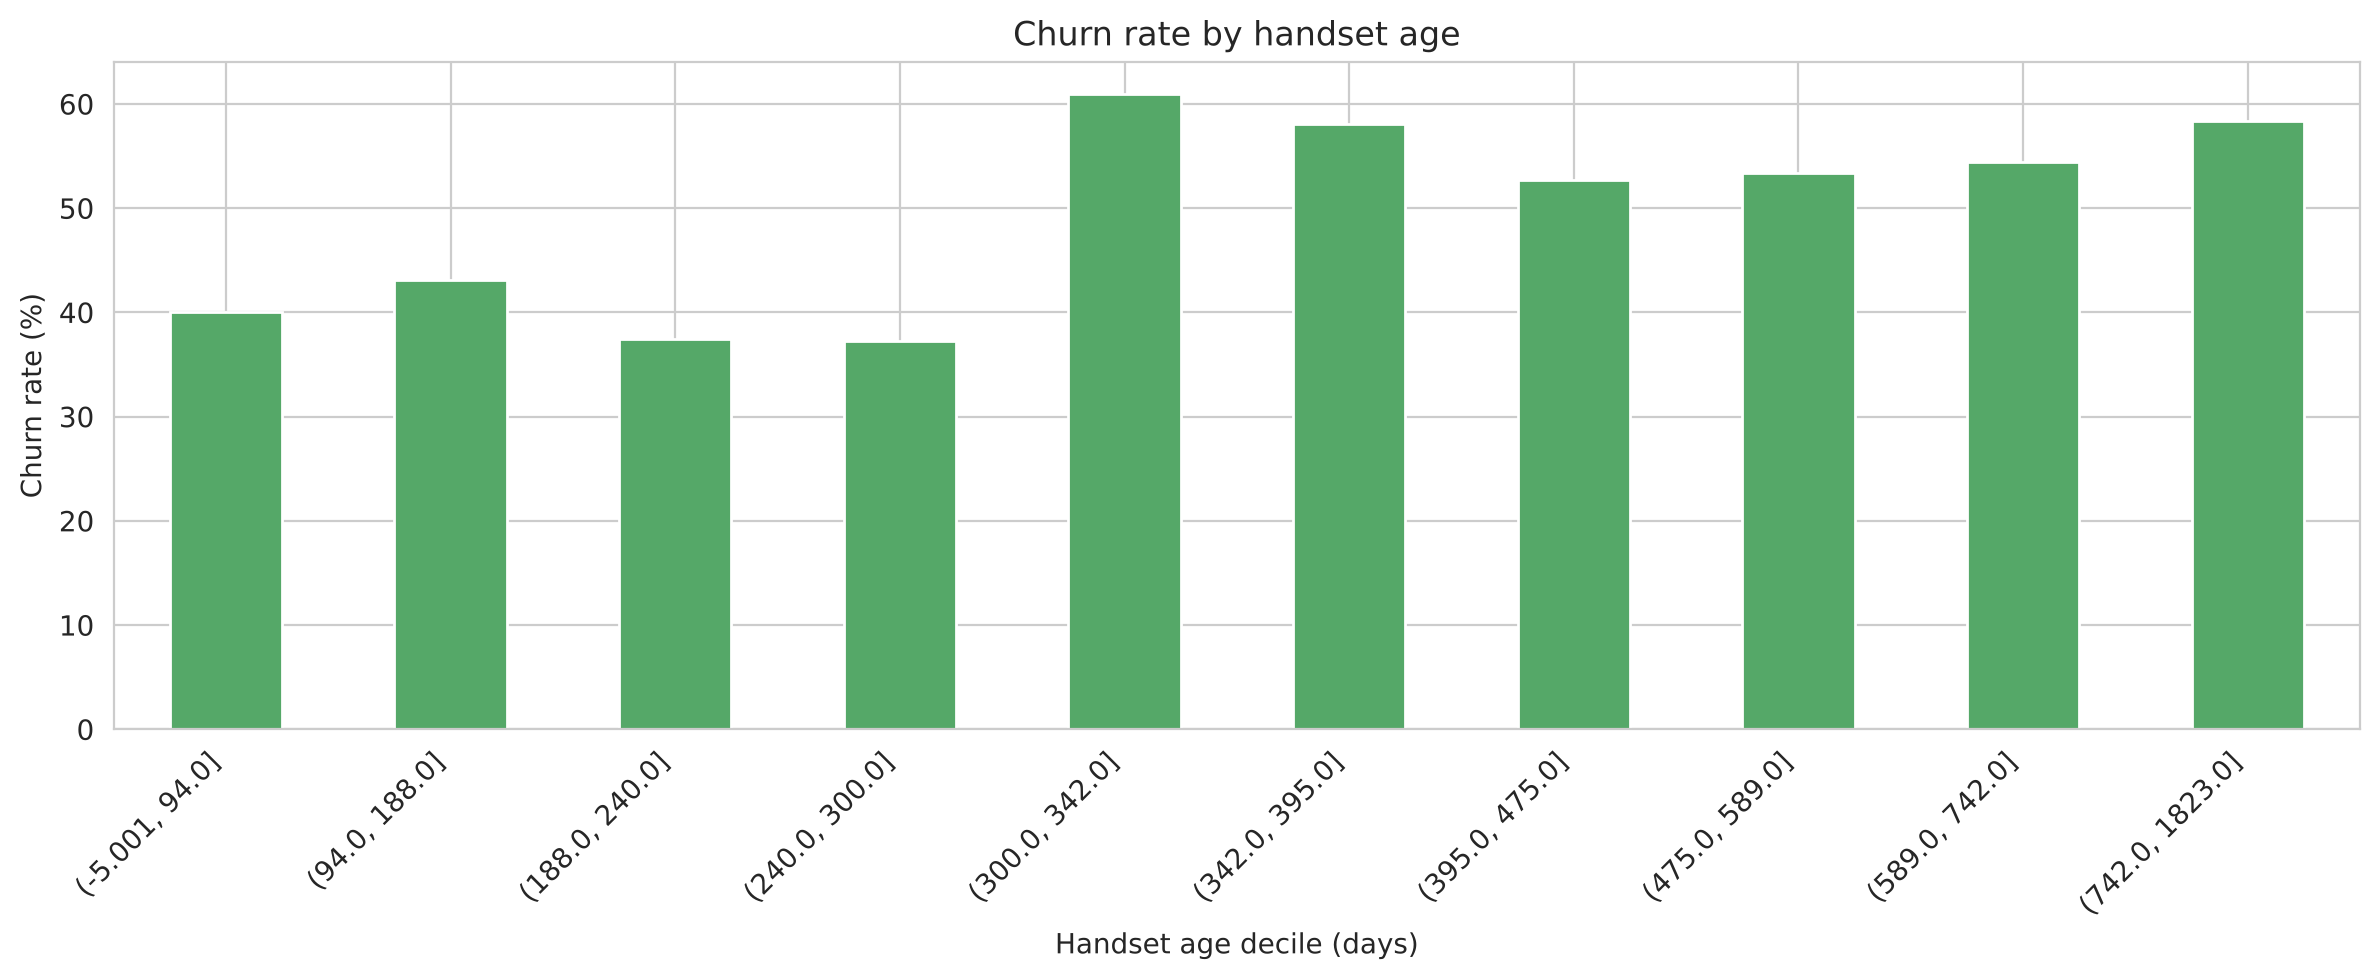

In [6]:
eq_bins = pd.qcut(df["eqpdays"], 10, duplicates="drop")
eq_rate = df.groupby(eq_bins, observed=True)[TARGET].mean() * 100
print(eq_rate.round(1).to_string())

plt.figure(figsize=(12, 5))
eq_rate.plot.bar(color="#55A868")
plt.ylabel("Churn rate (%)")
plt.xlabel("Handset age decile (days)")
plt.title("Churn rate by handset age")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 3.5 Recent usage trend and churn

We compare each customer's average usage over the last 3 months with the previous 6 months. A ratio below 1 means recent usage is lower than the longer-term norm. This is an early warning signal available before a customer leaves. (Note: this ratio is used as a *feature* in the model, not as the target. See Section 4.)

                 churn_rate_%  customers
(-0.001, 0.635]          62.5       9718
(0.635, 0.801]           50.9       9715
(0.801, 0.89]            49.6       9716
(0.89, 0.954]            46.6       9719
(0.954, 1.005]           47.9       9713
(1.005, 1.057]           47.4       9716
(1.057, 1.114]           47.4       9716
(1.114, 1.185]           47.5       9717
(1.185, 1.3]             47.9       9721
(1.3, 1.999]             50.6       9710


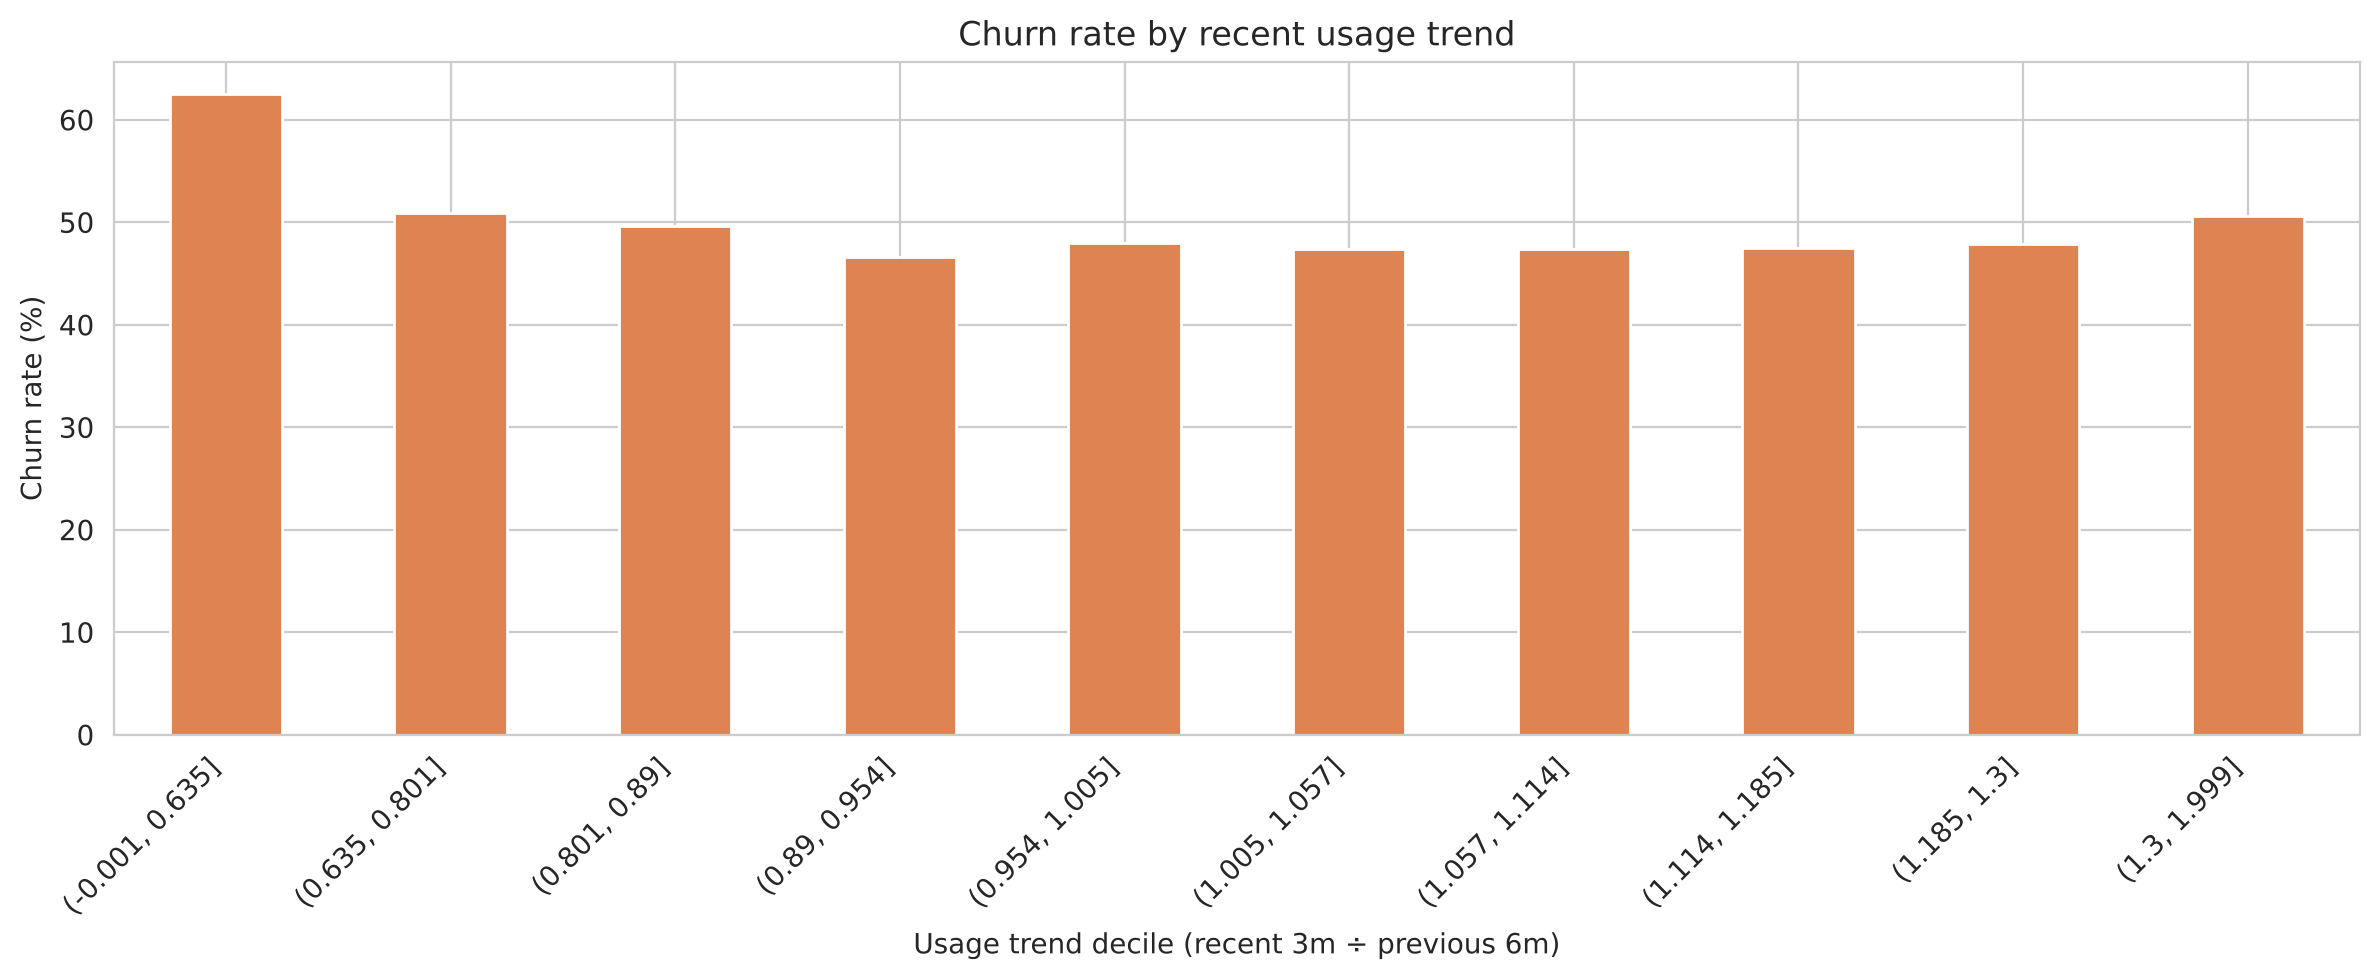

In [7]:
trend = df["avg3mou"] / (df["avg6mou"] + 1)
trend_bins = pd.qcut(trend, 10, duplicates="drop")
trend_rate = df.groupby(trend_bins, observed=True)[TARGET].agg(["mean", "size"])
trend_rate["mean"] *= 100
print(trend_rate.round(1).rename(columns={"mean": "churn_rate_%", "size": "customers"}).to_string())

plt.figure(figsize=(12, 5))
trend_rate["mean"].plot.bar(color="#DD8452")
plt.ylabel("Churn rate (%)")
plt.xlabel("Usage trend decile (recent 3m ÷ previous 6m)")
plt.title("Churn rate by recent usage trend")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 4. Problem definition and target choice

**Business question:** *Which customers are likely to leave in the next 1–2 months, and what would retaining them be worth?*

**Target: `churn`.** The dataset defines it as whether a customer left 31–60 days after the observation date. It is the real business outcome the client cares about, and it is measured after the features are observed, so the model predicts the future from the past.

**Why not a usage-drop target?** A usage-drop label (for example, `avg3mou < 0.7 × avg6mou`) is computed from features that the model would also receive. A model trained on it would learn the labelling rule rather than customer behaviour, and its score would be inflated. The check below shows the rule's relationship with the real churn outcome. We therefore use `churn` as the target and use usage trends only as features.

In [8]:
# Check: how does the usage-drop rule relate to the observed churn outcome?
usage_drop = (df["avg3mou"] < 0.7 * df["avg6mou"]).astype(int)
print(f"Customers matching the usage-drop rule: {usage_drop.mean():.1%}")
check = (df.assign(usage_drop=usage_drop)
           .groupby("usage_drop")[TARGET].agg(["mean", "size"])
           .rename(columns={"mean": "churn_rate", "size": "customers"}))
print(check.round(3).to_string())
print("\nA label built from features is not the same as the outcome; the rule is used only as a feature.")

Customers matching the usage-drop rule: 11.4%
            churn_rate  customers
usage_drop                       
0                0.482      88609
1                0.599      11391

A label built from features is not the same as the outcome; the rule is used only as a feature.


## 5. Feature engineering and leakage checks

**Leakage check.** Every feature must be known at the observation date, before the churn window. The data documentation describes the columns as averages, counts and changes measured over past periods, so the raw columns appear valid. This should be confirmed with the client, because the documentation is incomplete for some columns. The only columns removed are `Customer_ID` (an identifier) and `churn` (the target).

**Engineered features.** We add a few ratios that express behaviour in relative terms, so they transfer across customers with different usage levels:
- `usage_trend_3v6`, `revenue_trend_3v6`: recent vs. earlier usage and revenue.
- `care_calls_per_100min`: customer-care calls relative to usage (a dissatisfaction proxy).
- `dropped_call_share`: failed call share (a network quality proxy).
- `equip_age_years`: handset age in years, easier to read than days.

**Remaining leakage risk.** The life-to-date totals (`totcalls`, `totmou`, `totrev`, `adj*`, `avg*` over the customer's life) must have been measured before the observation date. The documentation does not state this, so Section 6.5 re-trains the model without them and checks whether performance holds.

In [9]:
TARGET = "churn"
ID_COL = "Customer_ID"

def add_features(data):
    out = data.copy()
    out["usage_trend_3v6"] = out["avg3mou"] / (out["avg6mou"] + 1)
    out["revenue_trend_3v6"] = out["avg3rev"] / (out["avg6rev"] + 1)
    out["care_calls_per_100min"] = 100 * out["custcare_Mean"] / (out["mou_Mean"] + 1)
    out["dropped_call_share"] = out["drop_vce_Mean"] / (out["plcd_vce_Mean"] + 1)
    out["equip_age_years"] = out["eqpdays"] / 365
    # Ratios can explode when a denominator is near zero: treat infinities as missing
    out = out.replace([np.inf, -np.inf], np.nan)
    return out

X = add_features(df.drop(columns=[TARGET, ID_COL]))
y = df[TARGET].astype(int)

# Split columns by type using the dtype rules that work on both pandas 2 and 3.
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

# Convert categorical values to plain strings and mark missing values explicitly.
for c in cat_cols:
    X[c] = X[c].map(lambda v: "missing" if pd.isna(v) else str(v))

print(f"Features: {X.shape[1]} total | {len(num_cols)} numeric | {len(cat_cols)} categorical")
print("Categorical columns:", cat_cols)

Features: 103 total | 82 numeric | 21 categorical
Categorical columns: ['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_webcap', 'ownrent', 'dwlltype', 'marital', 'infobase', 'HHstatin', 'dwllsize', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd']


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| churn rate:", round(y_train.mean(), 3))
print("Test: ", X_test.shape, "| churn rate:", round(y_test.mean(), 3))

Train: (80000, 103) | churn rate: 0.496
Test:  (20000, 103) | churn rate: 0.496


## 6. Models

We compare three models of increasing complexity:
1. **Logistic Regression**: a transparent baseline. Its coefficients are easy to explain.
2. **Random Forest**: many decision trees averaged together. Handles non-linear patterns.
3. **Gradient Boosting (HistGradientBoosting)**: trees built one after another, each correcting the last. Often the strongest on tabular data.

All three use the same preprocessing inside a Pipeline. Preprocessing is fitted on training data only, which prevents leakage from the test set. Model selection uses 5-fold cross-validation on the training set. The test set is used once, at the end, to report results.

In [11]:
def make_preprocessor():
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler()),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer(
        transformers=[
            ("num", numeric, num_cols),
            ("cat", categorical, cat_cols),
        ],
        remainder="drop",
    )

def make_models():
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=2000, class_weight="balanced"
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=150, max_depth=12, min_samples_leaf=5,
            class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE,
        ),
        "Gradient Boosting": HistGradientBoostingClassifier(
            learning_rate=0.05, max_iter=400, early_stopping=True,
            validation_fraction=0.1, class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
    }

def make_pipeline(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

### 6.1 Cross-validation on the training set

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1"}

cv_rows = []
for name, model in make_models().items():
    res = cross_validate(make_pipeline(model), X_train, y_train, cv=cv,
                         scoring=scoring, n_jobs=1)
    cv_rows.append({
        "Model": name,
        "CV ROC-AUC (mean)": res["test_roc_auc"].mean(),
        "CV ROC-AUC (std)": res["test_roc_auc"].std(),
        "CV PR-AUC (mean)": res["test_pr_auc"].mean(),
        "CV F1 (mean)": res["test_f1"].mean(),
    })
cv_results = pd.DataFrame(cv_rows).sort_values("CV ROC-AUC (mean)", ascending=False)
print(cv_results.round(4).to_string(index=False))

              Model  CV ROC-AUC (mean)  CV ROC-AUC (std)  CV PR-AUC (mean)  CV F1 (mean)
  Gradient Boosting             0.6899            0.0046            0.6731        0.6428
      Random Forest             0.6699            0.0051            0.6525        0.6338
Logistic Regression             0.6311            0.0018            0.6073        0.5961


### 6.2 Final training and test-set evaluation

In [13]:
fitted = {}
test_proba = {}
for name, model in make_models().items():
    pipe = make_pipeline(model)
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    test_proba[name] = pipe.predict_proba(X_test)[:, 1]

def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "Precision": precision_score(y_true, pred),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "Accuracy": accuracy_score(y_true, pred),
    }

test_results = pd.DataFrame(
    {name: evaluate(y_test, p) for name, p in test_proba.items()}
).T.round(4)
print("Test-set results (threshold 0.5):")
print(test_results.to_string())

Test-set results (threshold 0.5):
                     ROC-AUC  PR-AUC  Precision  Recall      F1  Accuracy
Logistic Regression   0.6347  0.6113     0.5926  0.6076  0.6000    0.5985
Random Forest         0.6687  0.6510     0.6038  0.6657  0.6332    0.6178
Gradient Boosting     0.6922  0.6813     0.6236  0.6606  0.6416    0.6342


### 6.3 Choose the final model

In [14]:
best_name = cv_results.iloc[0]["Model"]
best_pipe = fitted[best_name]
best_proba = test_proba[best_name]
best_row = test_results.loc[best_name]

print("=" * 70)
print(f"FINAL MODEL:        {best_name}")
print(f"PRIMARY METRIC:     ROC-AUC (cross-validated on training data, then tested)")
print(f"CV ROC-AUC:         {cv_results.iloc[0]['CV ROC-AUC (mean)']:.3f} "
      f"(± {cv_results.iloc[0]['CV ROC-AUC (std)']:.3f})")
print(f"TEST ROC-AUC:       {best_row['ROC-AUC']:.3f}")
print(f"TEST PR-AUC:        {best_row['PR-AUC']:.3f}")
print(f"TEST F1 (t=0.5):    {best_row['F1']:.3f}")
print("=" * 70)

FINAL MODEL:        Gradient Boosting
PRIMARY METRIC:     ROC-AUC (cross-validated on training data, then tested)
CV ROC-AUC:         0.690 (± 0.005)
TEST ROC-AUC:       0.692
TEST PR-AUC:        0.681
TEST F1 (t=0.5):    0.642


### 6.4 Confusion matrix

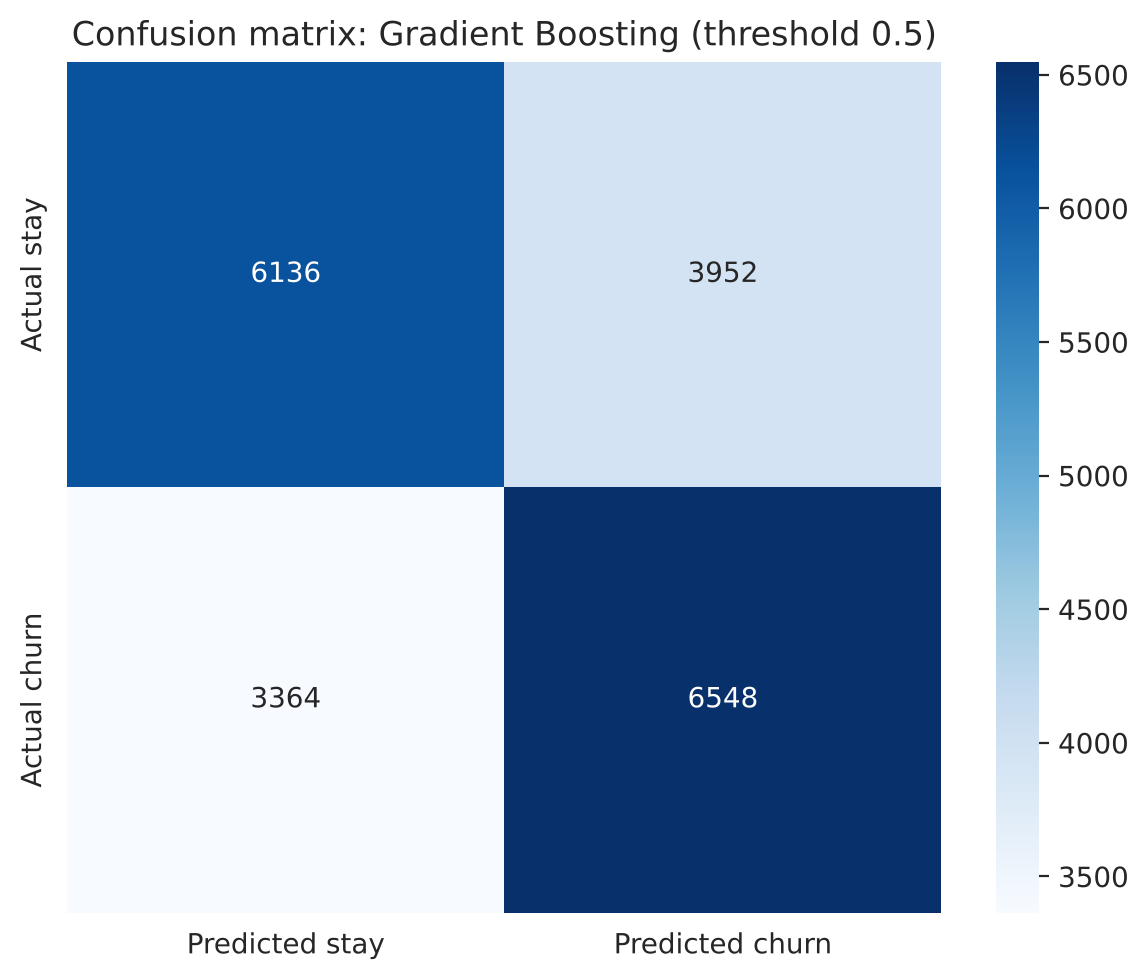

              precision    recall  f1-score   support

        Stay       0.65      0.61      0.63     10088
       Churn       0.62      0.66      0.64      9912

    accuracy                           0.63     20000
   macro avg       0.63      0.63      0.63     20000
weighted avg       0.63      0.63      0.63     20000



In [15]:
cm = confusion_matrix(y_test, best_proba >= 0.5)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted stay", "Predicted churn"],
            yticklabels=["Actual stay", "Actual churn"])
plt.title(f"Confusion matrix: {best_name} (threshold 0.5)")
plt.tight_layout()
plt.show()
print(classification_report(y_test, best_proba >= 0.5, target_names=["Stay", "Churn"]))

### 6.5 ROC and precision-recall curves (test set)

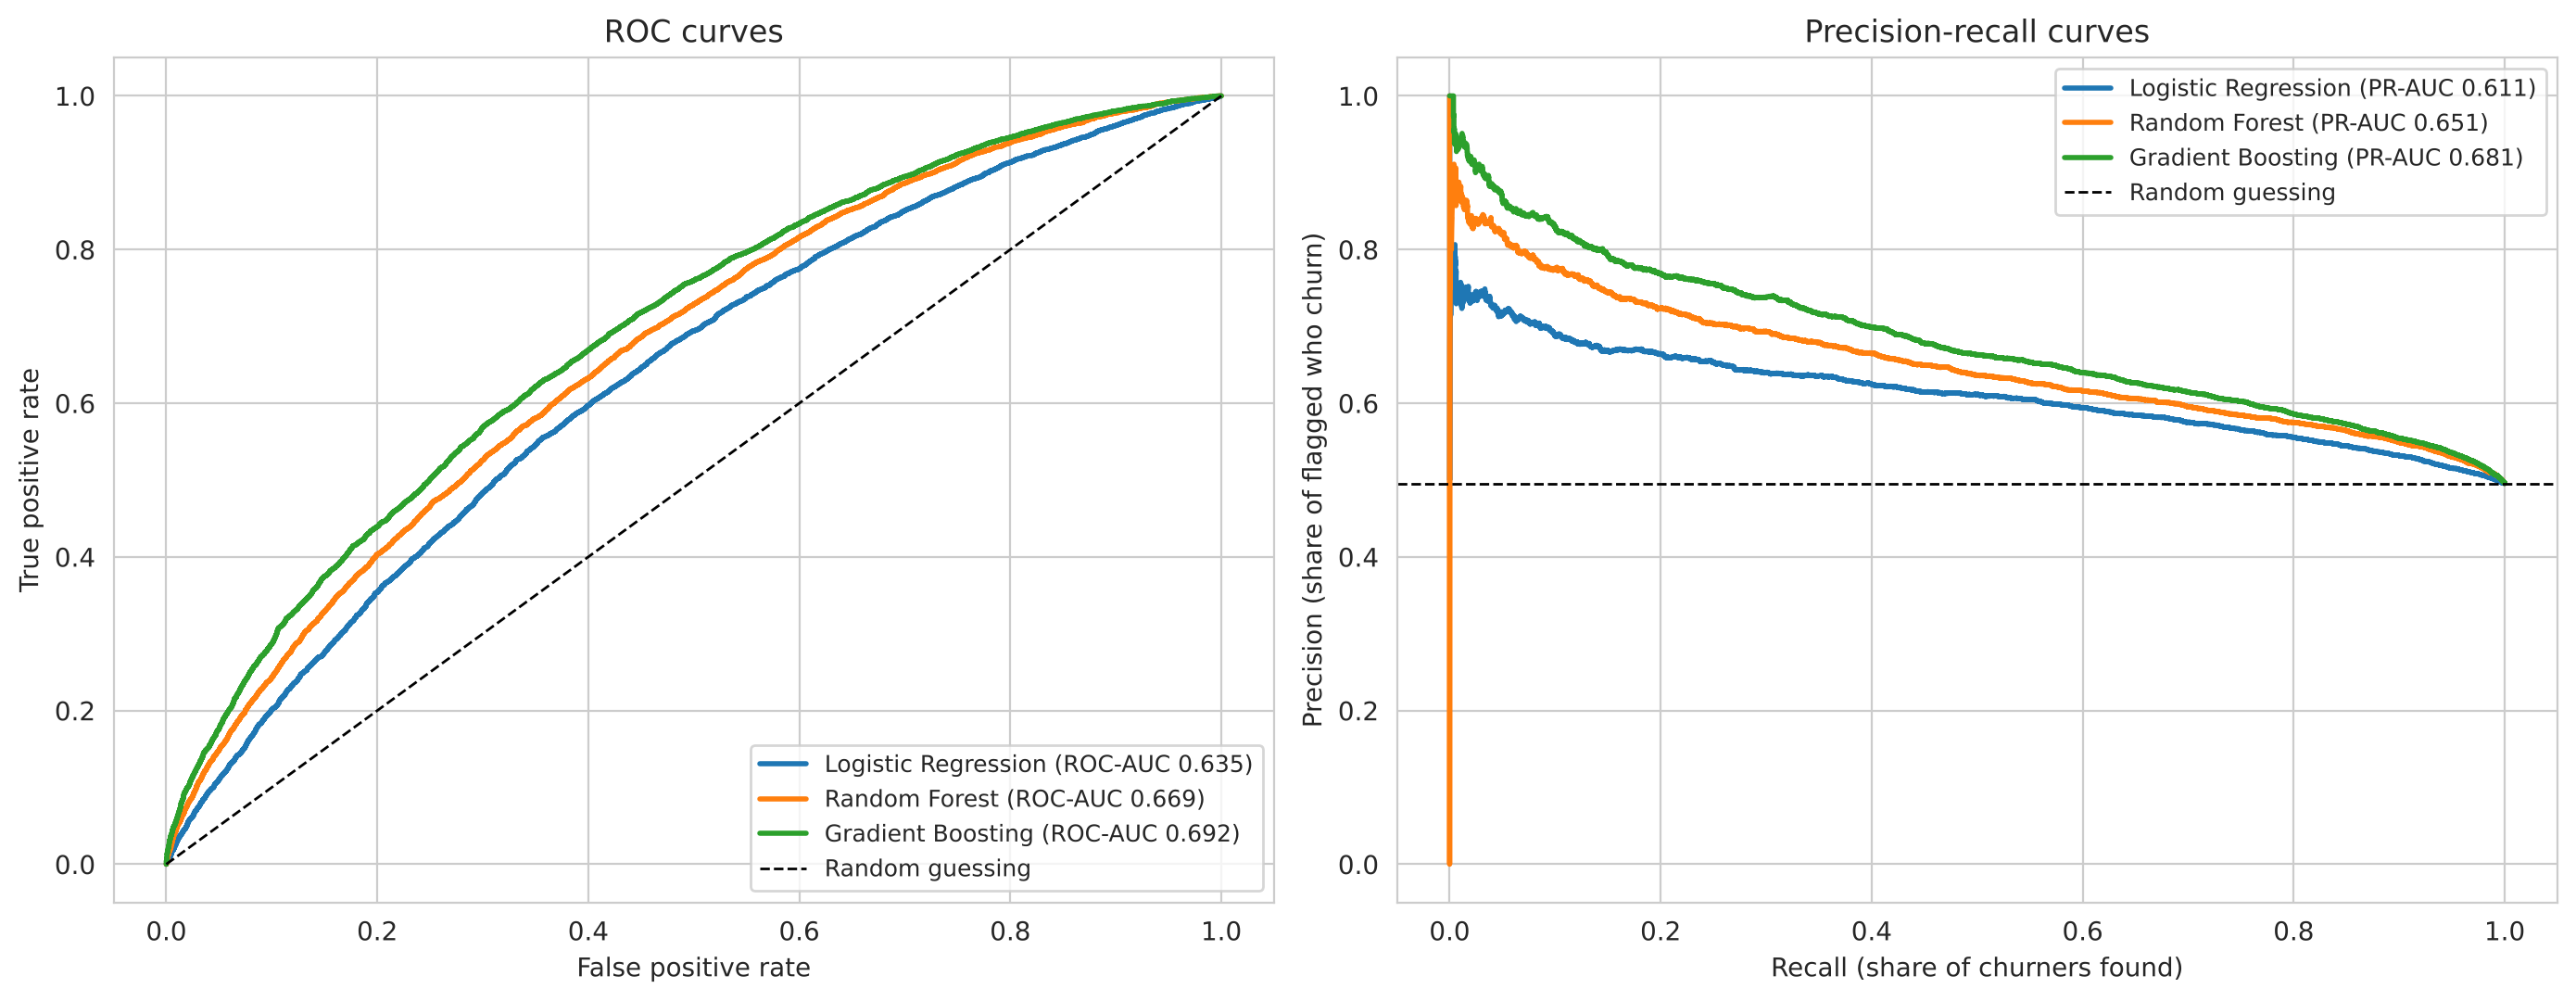

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (ROC-AUC {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, lw=2, label=f"{name} (PR-AUC {average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random guessing")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="Random guessing")
axes[1].set(xlabel="Recall (share of churners found)", ylabel="Precision (share of flagged who churn)", title="Precision-recall curves")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=9)
plt.tight_layout()
plt.show()

### 6.6 Robustness check: remove life-to-date totals

If the life-to-date totals were measured after the observation date, they would leak the outcome and inflate the score. We re-train the best model without them. A similar score means the result does not depend on those columns.

In [17]:
life_cols = ['totcalls', 'totmou', 'totrev', 'adjrev', 'adjmou', 'adjqty', 'avgrev', 'avgmou', 'avgqty']
Xr_train = X_train.drop(columns=life_cols)
Xr_test = X_test.drop(columns=life_cols)
rn = Xr_train.select_dtypes(include="number").columns.tolist()
rc = Xr_train.select_dtypes(exclude="number").columns.tolist()
robust_pre = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", RobustScaler())]), rn),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), rc),
], remainder="drop")
robust_model = Pipeline([("prep", robust_pre), ("model", HistGradientBoostingClassifier(
    learning_rate=0.05, max_iter=400, early_stopping=True, validation_fraction=0.1,
    class_weight="balanced", random_state=RANDOM_STATE))])
robust_model.fit(Xr_train, y_train)
robust_proba = robust_model.predict_proba(Xr_test)[:, 1]
full_auc = roc_auc_score(y_test, test_proba[best_name])
robust_auc = roc_auc_score(y_test, robust_proba)
print(f"Features removed: {len(life_cols)} life-to-date columns")
print(f"Test ROC-AUC with all features:           {full_auc:.3f}")
print(f"Test ROC-AUC without life-to-date totals: {robust_auc:.3f}")
print("A small difference means the score does not rely on the life-to-date totals.")

Features removed: 9 life-to-date columns
Test ROC-AUC with all features:           0.692
Test ROC-AUC without life-to-date totals: 0.690
A small difference means the score does not rely on the life-to-date totals.


## 7. Model interpretation

Feature importance is measured by **permutation**: for each feature, we shuffle its values on held-out data and record how much the ROC-AUC drops. A large drop means the model relies on that feature. This works for any model, unlike built-in importances, which only some models provide.

Importance shows what the model uses, not why customers leave. The business interpretation in Section 8 should be checked against domain knowledge.

,feature,importance_mean,importance_std
97,eqpdays,0.0474,0.0025
48,months,0.0345,0.0030
9,change_mou,0.0264,0.0029
2,totmrc_Mean,0.0183,0.0019
73,hnd_price,0.0149,0.0005
1,mou_Mean,0.0141,0.0008
49,uniqsubs,0.0090,0.0018
98,usage_trend_3v6,0.0068,0.0030
62,avgqty,0.0067,0.0012
90,ethnic,0.0059,0.0033


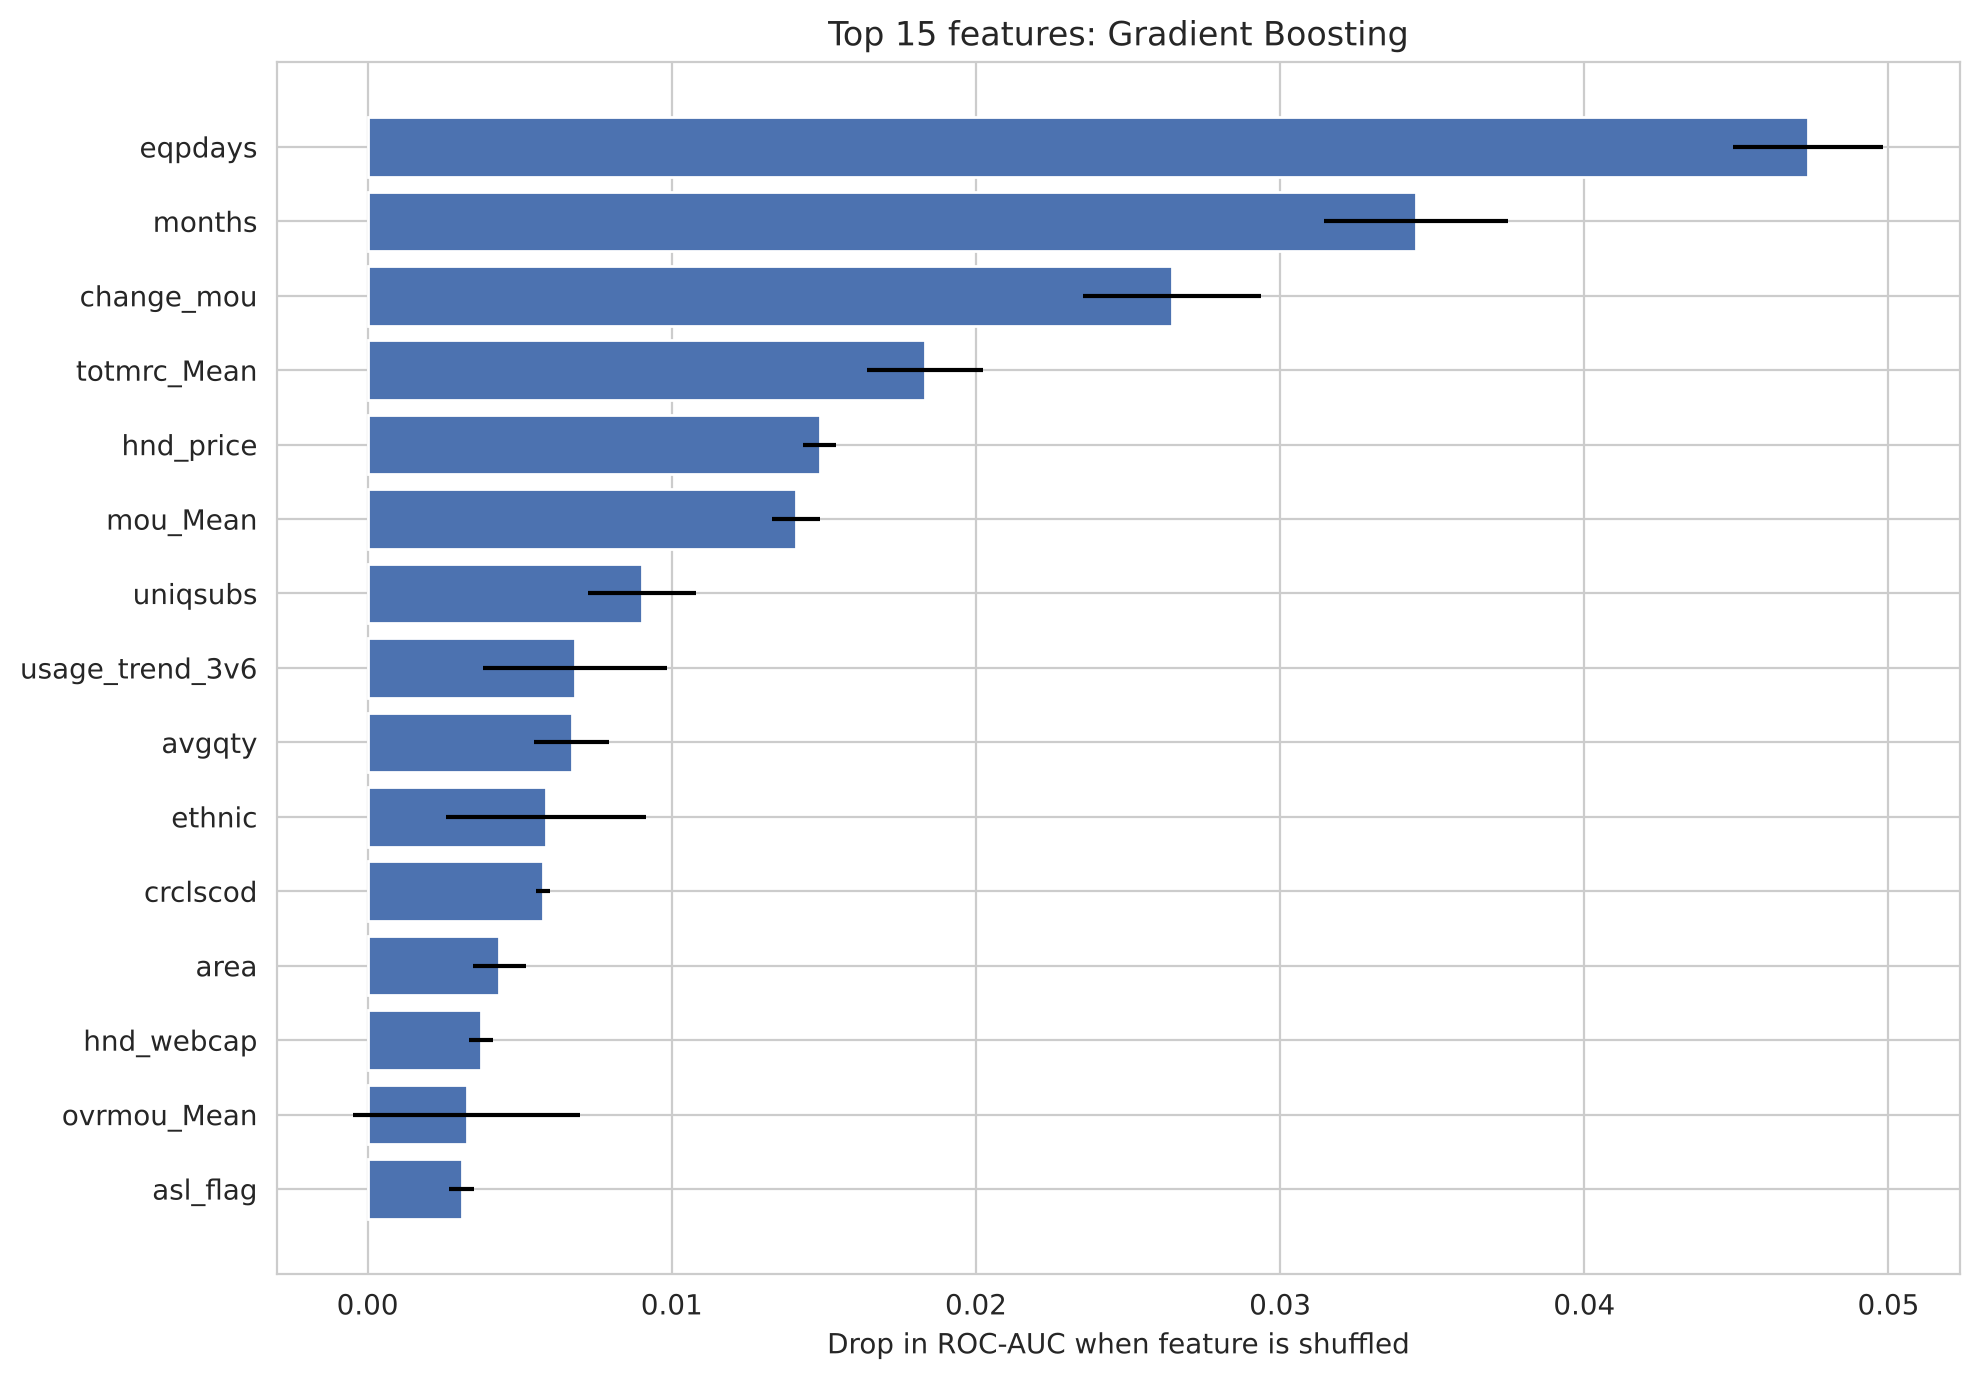

In [18]:
sample_idx = X_test.sample(n=min(2000, len(X_test)), random_state=RANDOM_STATE).index
perm = permutation_importance(
    best_pipe, X_test.loc[sample_idx], y_test.loc[sample_idx],
    scoring="roc_auc", n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1,
)
importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values("importance_mean", ascending=False)

display(importance.head(15).round(4))

top = importance.head(15).iloc[::-1]
plt.figure(figsize=(10, 7))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"], color="#4C72B0")
plt.xlabel("Drop in ROC-AUC when feature is shuffled")
plt.title(f"Top 15 features: {best_name}")
plt.tight_layout()
plt.show()

## 8. Business impact and proposal

The model gives each customer a churn probability. The business decision is *who to contact*, *how many*, and *what it returns*.

**Campaign economics.** For each contacted customer:
- Only a customer who would have churned can be saved, so expected saves = contacted churners × save rate.
- Revenue retained = saves × monthly revenue × horizon.
- Cost = number of contacts × cost per offer.

**Break-even probability.** A contact pays for itself only if the customer's chance of churning is at least `cost ÷ (save rate × monthly revenue × horizon)`.

**Budget.** A retention team can only contact a limited share of customers. So the practical question is: *if we can contact K% of customers, which K% should they be?* The model's value is measured against **random selection with the same budget**: how many more churners does it reach, and how many more customers does that save?

### 8.1 Assumptions

Monthly revenue comes from the data. Cost per offer, save rate, horizon and the budget share are **not in the data**. They are placeholders to replace with the client's figures. Section 8.4 shows how the conclusion changes with the save rate.

In [19]:
ASSUMPTIONS = {
    "monthly_revenue_per_customer": float(df["rev_Mean"].median()),  # from data
    "horizon_months": 12,      # revenue counted over the next 12 months (no discounting)
    "cost_per_offer": 10.0,    # placeholder: cost of one retention contact, in $
    "save_rate": 0.25,         # placeholder: share of contacted churners who are retained
}
BUDGET_SHARE = 0.20            # placeholder: share of customers the team can contact
a = ASSUMPTIONS
SCALE = len(df) / len(y_test)  # test-set counts -> full customer base

BREAKEVEN_P = a["cost_per_offer"] / (a["save_rate"] * a["monthly_revenue_per_customer"] * a["horizon_months"])

for k, v in ASSUMPTIONS.items():
    print(f"{k:32s}: {v}")
print(f"{'budget_share':32s}: {BUDGET_SHARE}")
print(f"{'break-even churn probability':32s}: {BREAKEVEN_P:.3f}")
print(f"{'scale factor (test -> base)':32s}: {SCALE:.2f}")

monthly_revenue_per_customer    : 48.195
horizon_months                  : 12
cost_per_offer                  : 10.0
save_rate                       : 0.25
budget_share                    : 0.2
break-even churn probability    : 0.069
scale factor (test -> base)     : 5.00


### 8.2 Is contacting a customer worth it?

In [20]:
share_above = (best_proba >= BREAKEVEN_P).mean()
print(f"Customers whose predicted churn probability is at or above break-even: {share_above:.1%}")
if share_above > 0.5:
    print("Under these assumptions most customers are worth contacting. "
          "The binding constraint is therefore the budget, not profitability.")
else:
    print("Under these assumptions only a minority of customers are worth contacting.")

Customers whose predicted churn probability is at or above break-even: 100.0%
Under these assumptions most customers are worth contacting. The binding constraint is therefore the budget, not profitability.


### 8.3 Budget-constrained comparison: model vs random targeting

Budget                        10%                                  20%                                  30%                          
Strategy                   Random Model (Gradient Boosting)     Random Model (Gradient Boosting)     Random Model (Gradient Boosting)
Customers contacted       10000.0                   10000.0    20000.0                   20000.0    30000.0                   30000.0
Churners reached           4956.0                    7855.0     9912.0                   14755.0    14868.0                   20785.0
Customers saved            1239.0                    1964.0     2478.0                    3689.0     3717.0                    5196.0
Revenue retained ($)     716563.0                 1135715.0  1433127.0                 2133352.0  2149690.0                 3005199.0
Campaign cost ($)        100000.0                  100000.0   200000.0                  200000.0   300000.0                  300000.0
Net impact ($)           616563.0                 1035715.0  1233127.0                 1933352.0  1849690.0                 2705199.0
Extra saves vs random         NaN                     725.0        NaN                    1211.0        NaN                    1479.0
Extra net vs random ($)       NaN                  419152.0        NaN                  700225.0        NaN                  855509.0


Churner-capture lift vs random (model / random):
  Budget 10%: 1.58x
  Budget 20%: 1.49x
  Budget 30%: 1.40x


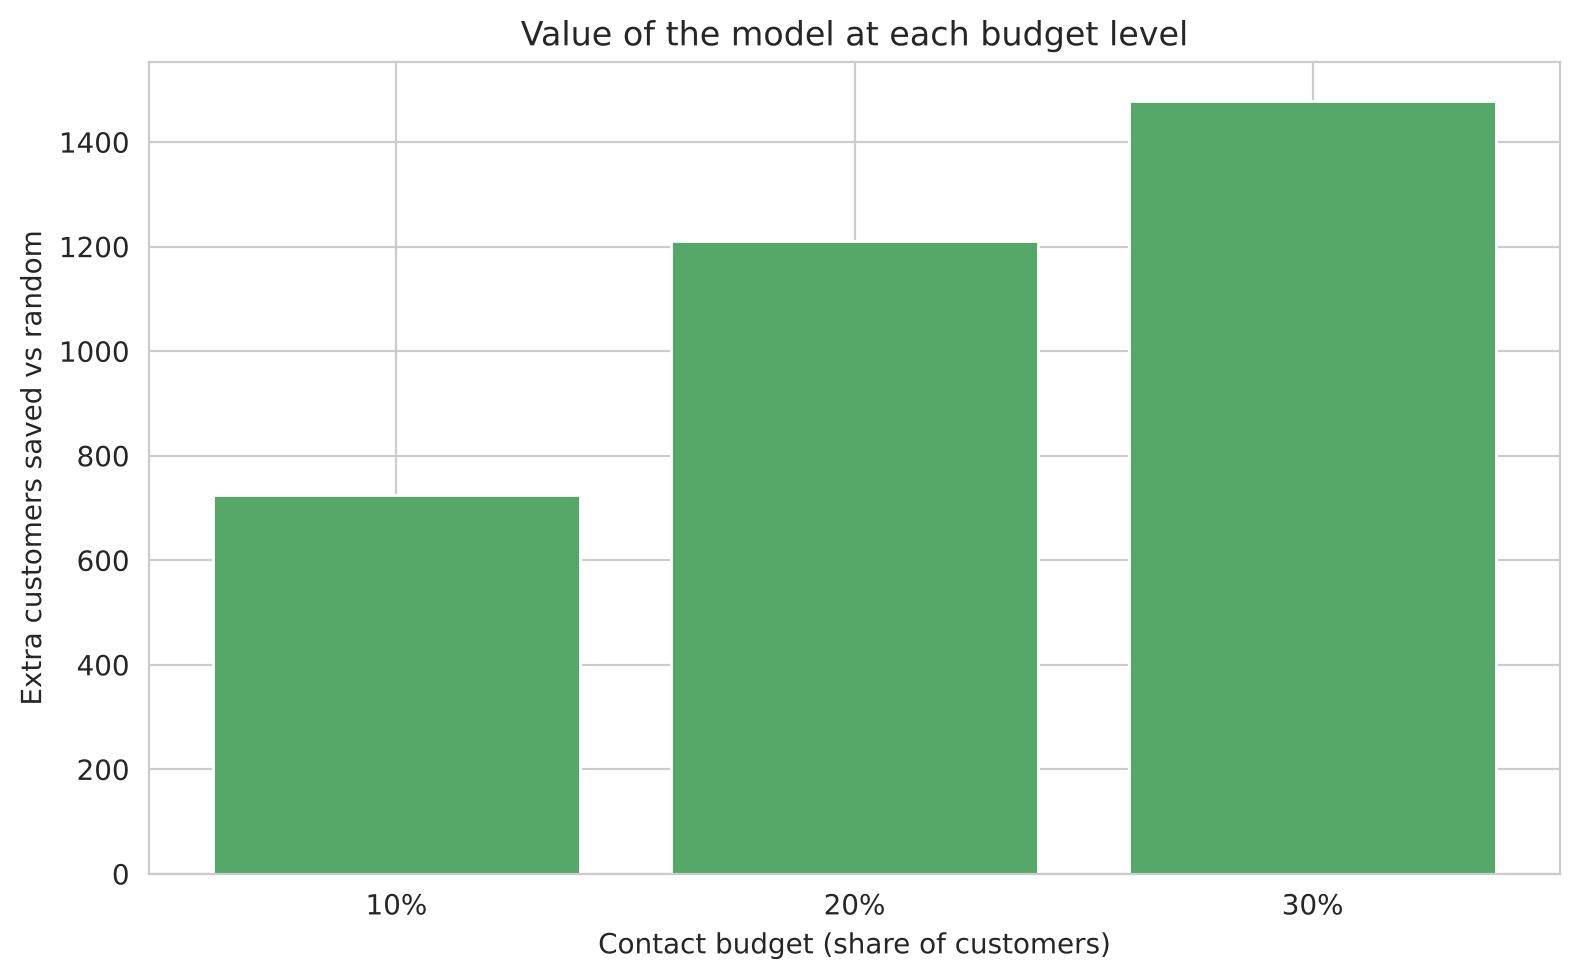

In [21]:
def top_share_mask(scores, share):
    """True for the `share` fraction of customers with the highest scores."""
    k = int(round(share * len(scores)))
    mask = np.zeros(len(scores), dtype=bool)
    mask[np.argsort(-scores)[:k]] = True
    return mask

def economics(contacted, reached):
    """Expected outcome of contacting `contacted` customers, `reached` of whom churn."""
    saves = reached * a["save_rate"]
    revenue = saves * a["monthly_revenue_per_customer"] * a["horizon_months"]
    cost = contacted * a["cost_per_offer"]
    return {
        "Customers contacted": contacted * SCALE,
        "Churners reached": reached * SCALE,
        "Customers saved": saves * SCALE,
        "Revenue retained ($)": revenue * SCALE,
        "Campaign cost ($)": cost * SCALE,
        "Net impact ($)": (revenue - cost) * SCALE,
    }

y_arr = y_test.values
total_churners = y_arr.sum()
rows = []
for share in [0.10, 0.20, 0.30]:
    n_contact = int(round(share * len(y_arr)))
    model_reached = (top_share_mask(best_proba, share) & (y_arr == 1)).sum()
    random_reached = share * total_churners  # expected value for random selection

    m = economics(n_contact, model_reached)
    r = economics(n_contact, random_reached)
    rows.append({"Budget": f"{share:.0%}", "Strategy": "Random", **r})
    rows.append({"Budget": f"{share:.0%}", "Strategy": f"Model ({best_name})", **m,
                 "Extra saves vs random": (m["Customers saved"] - r["Customers saved"]),
                 "Extra net vs random ($)": (m["Net impact ($)"] - r["Net impact ($)"])})

budget_df = pd.DataFrame(rows)
display(budget_df.round(0).set_index(["Budget", "Strategy"]).T)

lift_rows = budget_df[budget_df["Strategy"].str.startswith("Model")]
lift = lift_rows["Churners reached"].values / budget_df[budget_df["Strategy"] == "Random"]["Churners reached"].values
print("\nChurner-capture lift vs random (model / random):")
for b, l in zip(lift_rows["Budget"], lift):
    print(f"  Budget {b}: {l:.2f}x")

plt.figure(figsize=(8, 5))
plt.bar(lift_rows["Budget"], lift_rows["Extra saves vs random"] * 1, color="#55A868")
plt.ylabel("Extra customers saved vs random")
plt.xlabel("Contact budget (share of customers)")
plt.title("Value of the model at each budget level")
plt.tight_layout()
plt.show()

### 8.3b Cumulative gains: share of churners reached by contact budget

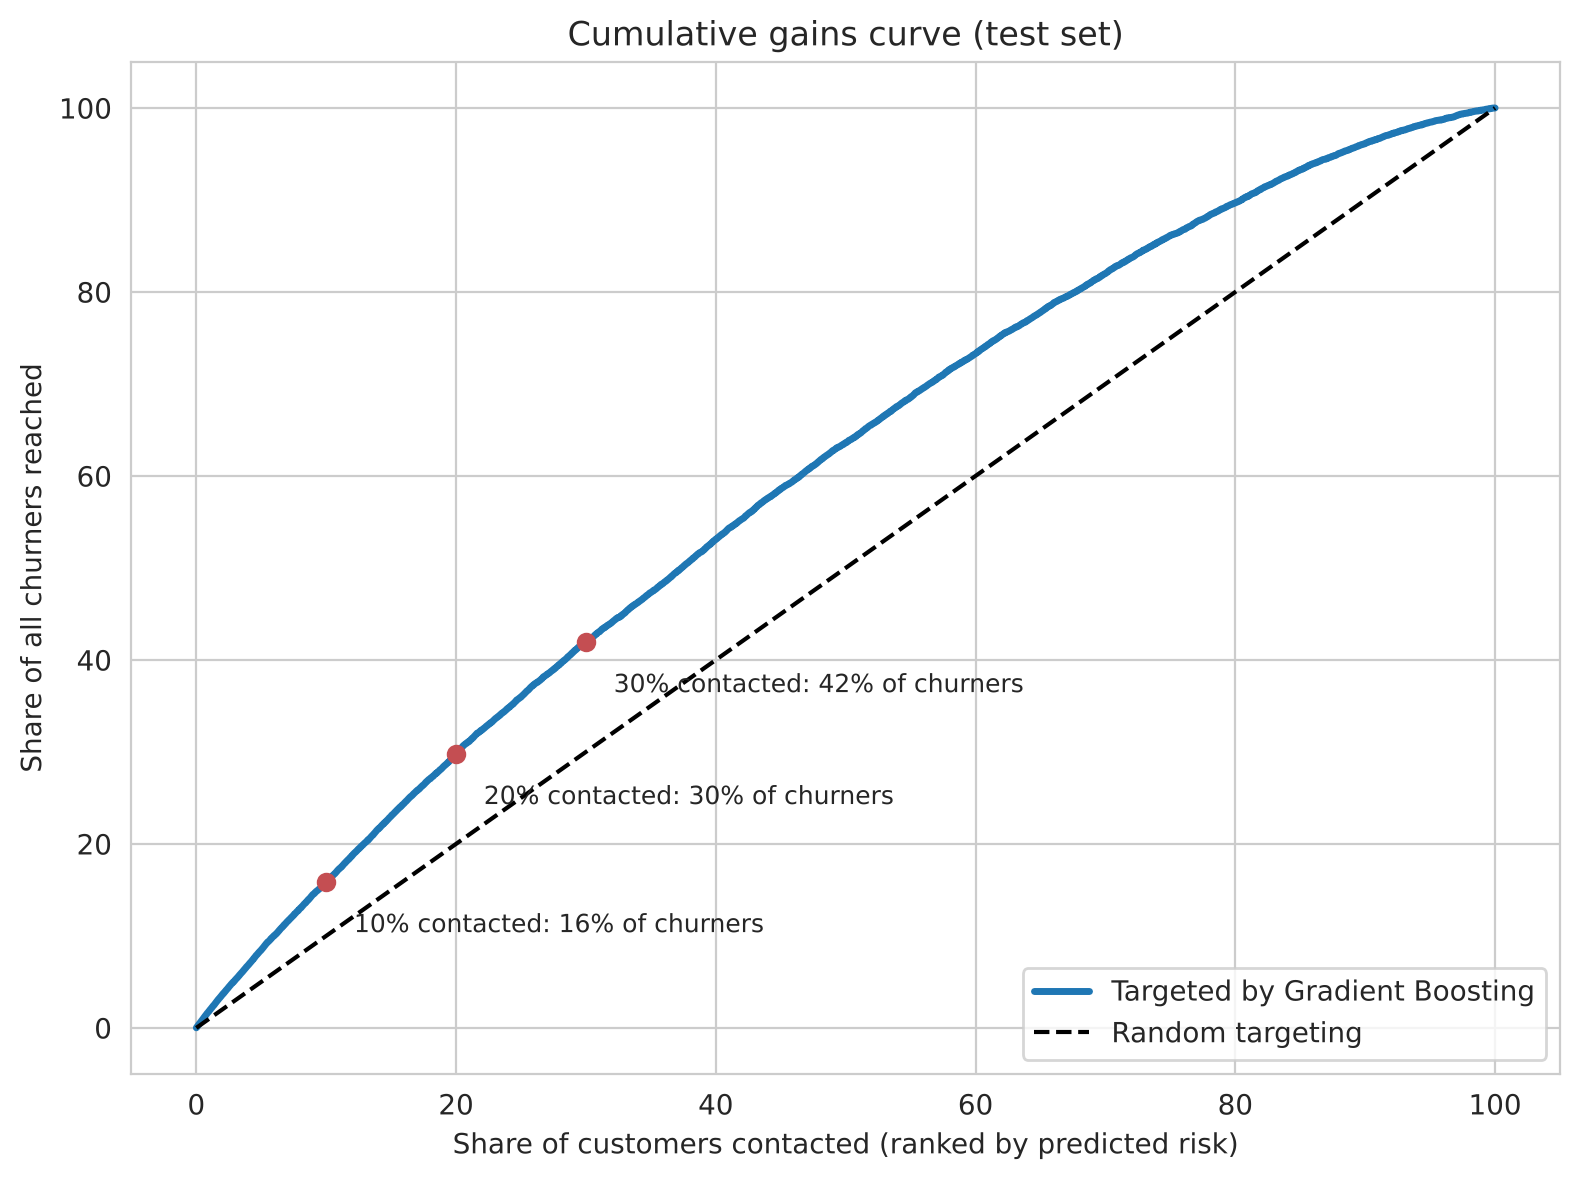

In [22]:
order = np.argsort(-best_proba)
cum_churn = np.cumsum(y_arr[order]) / total_churners
share_contacted = np.arange(1, len(order) + 1) / len(order)
plt.figure(figsize=(8, 6))
plt.plot(share_contacted * 100, cum_churn * 100, lw=2.5, label=f"Targeted by {best_name}")
plt.plot([0, 100], [0, 100], "k--", lw=1.5, label="Random targeting")
for b in [0.10, 0.20, 0.30]:
    idx = int(round(b * len(order))) - 1
    plt.scatter([b * 100], [cum_churn[idx] * 100], zorder=5, color="#C44E52")
    plt.annotate(f"{b:.0%} contacted: {cum_churn[idx]:.0%} of churners", (b * 100, cum_churn[idx] * 100),
                 textcoords="offset points", xytext=(10, -18), fontsize=9)
plt.xlabel("Share of customers contacted (ranked by predicted risk)")
plt.ylabel("Share of all churners reached")
plt.title("Cumulative gains curve (test set)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 8.4 Sensitivity to the save rate

Offer cost and the budget are the same for both strategies, so the model's advantage depends only on the number of extra churners it reaches. The save rate scales that advantage, so this check shows how large the gain is under different assumptions.

In [23]:
share = BUDGET_SHARE
n_contact = int(round(share * len(y_arr)))
model_reached = (top_share_mask(best_proba, share) & (y_arr == 1)).sum()
random_reached = share * total_churners

sens_rows = []
for sr in [0.10, 0.15, 0.25, 0.35, 0.50]:
    a_sr = {**a, "save_rate": sr}
    saves_m = model_reached * sr
    saves_r = random_reached * sr
    net_m = (saves_m * a_sr["monthly_revenue_per_customer"] * a_sr["horizon_months"]
             - n_contact * a_sr["cost_per_offer"]) * SCALE
    net_r = (saves_r * a_sr["monthly_revenue_per_customer"] * a_sr["horizon_months"]
             - n_contact * a_sr["cost_per_offer"]) * SCALE
    sens_rows.append({"Save rate": f"{sr:.0%}",
                      "Net impact: model ($M)": net_m / 1e6,
                      "Net impact: random ($M)": net_r / 1e6,
                      "Model advantage ($M)": (net_m - net_r) / 1e6})
sens_df = pd.DataFrame(sens_rows)
print(f"Budget fixed at {share:.0%} of customers ({n_contact:,} in the test set).")
print(sens_df.round(2).to_string(index=False))

# Break-even save rate for the model-targeted group
be_save = (n_contact * a["cost_per_offer"]) / (model_reached * a["monthly_revenue_per_customer"] * a["horizon_months"])
print(f"\nBreak-even save rate for the model-targeted group: {be_save:.1%}")

Budget fixed at 20% of customers (4,000 in the test set).
Save rate  Net impact: model ($M)  Net impact: random ($M)  Model advantage ($M)
      10%                    0.65                     0.37                  0.28
      15%                    1.08                     0.66                  0.42
      25%                    1.93                     1.23                  0.70
      35%                    2.79                     1.81                  0.98
      50%                    4.07                     2.67                  1.40

Break-even save rate for the model-targeted group: 2.3%


### 8.5 Proposal summary

In [24]:
share = BUDGET_SHARE
n_total = len(df)
m_row = budget_df[(budget_df["Budget"] == f"{share:.0%}") & budget_df["Strategy"].str.startswith("Model")].iloc[0]
r_row = budget_df[(budget_df["Budget"] == f"{share:.0%}") & (budget_df["Strategy"] == "Random")].iloc[0]
trend_low = trend_rate["mean"].iloc[0]
trend_mid = trend_rate["mean"].iloc[len(trend_rate) // 2]

print(f"""
PROPOSAL: Targeted retention campaign driven by the churn model

PROBLEM
  About {y.mean():.0%} of customers churned in the 31–60 days after observation.
  Customers in the lowest recent-usage trend group churn at {trend_low:.1f}%,
  versus {trend_mid:.1f}% for the middle group. Customers with handsets older than about 300 days churn at 50–61%, versus about 37–43% for newer handsets (Section 3.4).

SOLUTION
  {best_name} scores each customer's churn risk using {X.shape[1]} features.
  Test ROC-AUC: {best_row['ROC-AUC']:.3f} | Test PR-AUC: {best_row['PR-AUC']:.3f}.
  The model is useful for ranking customers, but not for near-certain predictions.

RECOMMENDED ACTION
  1. Contact the top {share:.0%} of customers by risk score (about {int(share * n_total):,} customers).
  2. Offer a retention incentive, prioritising customers with older handsets and falling usage.
  3. Hold out a random control group of similar size to measure the true effect.

EXPECTED IMPACT (under the stated assumptions, Section 8.1)
  Churners reached: {m_row['Churners reached']:,.0f} with the model vs {r_row['Churners reached']:,.0f} with random selection.
  Extra customers saved vs random: {m_row['Extra saves vs random']:,.0f}
  Revenue retained over {a['horizon_months']} months (model): ${m_row['Revenue retained ($)']:,.0f}
  Campaign cost (model): ${m_row['Campaign cost ($)']:,.0f}
  Net impact (model): ${m_row['Net impact ($)']:,.0f}
  Extra net impact vs random: ${m_row['Extra net vs random ($)']:,.0f}

KEY RISKS AND LIMITATIONS
  - Save rate, offer cost, horizon and budget are assumptions, not measured values.
  - The data is a single snapshot; it does not show whether the model stays accurate over time.
  - The model shows association, not causation. The control group is needed to confirm the offer works.
""")


PROPOSAL: Targeted retention campaign driven by the churn model

PROBLEM
  About 50% of customers churned in the 31–60 days after observation.
  Customers in the lowest recent-usage trend group churn at 62.5%,
  versus 47.4% for the middle group. Customers with handsets older than about 300 days churn at 50–61%, versus about 37–43% for newer handsets (Section 3.4).

SOLUTION
  Gradient Boosting scores each customer's churn risk using 103 features.
  Test ROC-AUC: 0.692 | Test PR-AUC: 0.681.
  The model is useful for ranking customers, but not for near-certain predictions.

RECOMMENDED ACTION
  1. Contact the top 20% of customers by risk score (about 20,000 customers).
  2. Offer a retention incentive, prioritising customers with older handsets and falling usage.
  3. Hold out a random control group of similar size to measure the true effect.

EXPECTED IMPACT (under the stated assumptions, Section 8.1)
  Churners reached: 14,755 with the model vs 9,912 with random selection.
  Extra cu

### 8.6 Next steps

1. **Replace the placeholder assumptions** (offer cost, save rate, horizon, budget share) with figures from the client's finance or marketing team.
2. **Run a controlled pilot:** contact the model-targeted group, hold out a random control group, and compare churn rates.
3. **Monitor and retrain:** check that ROC-AUC holds on new months of data, and retrain when it drops.
4. **Segment the offer:** for example, a handset upgrade for older devices, and a usage plan review for customers whose usage is falling.

## 9. Conclusion

The notebook follows the full path from data to proposal: market context, validation, EDA, a justified target, features checked for leakage, three models compared with cross-validation, a robustness check, and a quantified recommendation with explicit assumptions.

The best model is **Gradient Boosting** with a **test ROC-AUC of about 0.69**. This is a modest level of separation, so the model is best used to rank customers for a targeted campaign with a control group, not to make certain predictions. Its value comes from reaching more churners than random selection with the same budget (Section 8.3), and the size of the gain depends on the save rate, which must be measured in a pilot.

The main methodological choice is the target. A usage-drop label built from the same features would let the model learn a formula rather than customer behaviour, so the observed `churn` outcome is used instead.

## References

[1] Reichheld, F. F., & Sasser, W. E., Jr. (1990). Zero defections: Quality comes to services. *Harvard Business Review*. https://www.bain.com/el/insights/zero-defections-quality-comes-to-services-harvard-business-review-hbr/

[2] Gallo, A. (2014, October 29). The value of keeping the right customers. *Harvard Business Review*. https://hbr.org/2014/10/the-value-of-keeping-the-right-customers

[3] Yahoo Finance. AT&T raising 2 fees customers pay monthly (reports AT&T Q1 2026 postpaid phone churn of 0.89%). https://finance.yahoo.com/technology/articles/t-raising-2-fees-customers-173600770.html

[4] PhoneArena. AT&T adds more postpaid phone subscribers during Q2 (reports AT&T Q2 2026 postpaid phone churn of 0.86%). https://www.phonearena.com/news/at-t-adds-more-postpaid-phone-subscribers-during-q2_id182058

[5] Teradata Center for Customer Relationship Management, Fuqua School of Business, Duke University. Datasets (churn data). http://www.fuqua.duke.edu/centers/ccrm/datasets/download.html

[6] Journal of Big Data (2024). Literature review of telecom churn models, including a Duke (Teradata Center) data model with AUC 0.67. https://journalofbigdata.springeropen.com/articles/10.1186/s40537-024-01020-6/tables/1

[7] Loyalty business model. Wikipedia (notes that Carroll and Reichheld, 1992, dispute the retention-profit calculations). https://en.wikipedia.org/wiki/Loyalty_business_model

[8] Generative AI disclosure: *[https://claude.ai/chat/fadbc04b-b6ed-498d-b929-37f1f02efb5c]*
